# Cubic splines

We simulate data from a known regression function and try to recover it. Global polynomials are the first idea; then we fit a different polynomial on each interval, and add restrictions one by one (continuity, continuity of the first derivative, continuity of the second derivative) until we get a cubic spline.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial
from scipy.stats import t
from scipy.interpolate import BSpline, LSQUnivariateSpline
from ipywidgets import interact, IntSlider

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
pi_color    = '#cfe8f3'
true_color  = '#333333'

## The data

In [3]:
def m(x):
    return 3*x - 3*x**2 + x**3 - 0.1*x**4

In [4]:
alpha = 0.05
n = 30

rng = np.random.default_rng(111)
x = np.linspace(0, 3, n)
Y = m(x) + rng.normal(0, 0.15, n)

x_grid = np.linspace(0, 3, 300)
m_grid = m(x_grid)

In [5]:
def plot_data(ax, legend=True):
    ax.plot(x_grid, m_grid, '--', color=true_color, lw=1.5, label='Regression function')
    ax.plot(x, Y, 'o', color=point_color, markersize=6, markeredgecolor='white', markeredgewidth=0.5,
            label='Observed data')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_ylim(-0.4, 1.9)
    ax.grid(True, alpha=0.25)
    if legend:
        ax.legend(loc='upper center', ncol=3, framealpha=1, edgecolor='none')

def shared_legend(fig, ax):
    # One legend for all the panels of a figure, above them
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=len(labels), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.96))

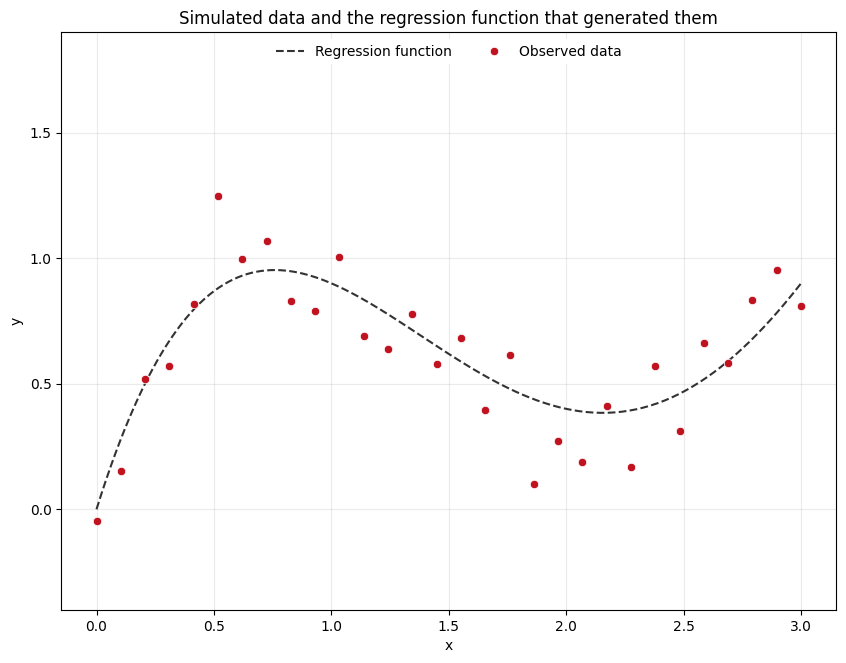

In [6]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_data(ax)
ax.set_title('Simulated data and the regression function that generated them');

## Global polynomials

We fit polynomials of degree 1 to 4 by least squares. The regression function is a polynomial of degree 4, so the last one is the correct model.

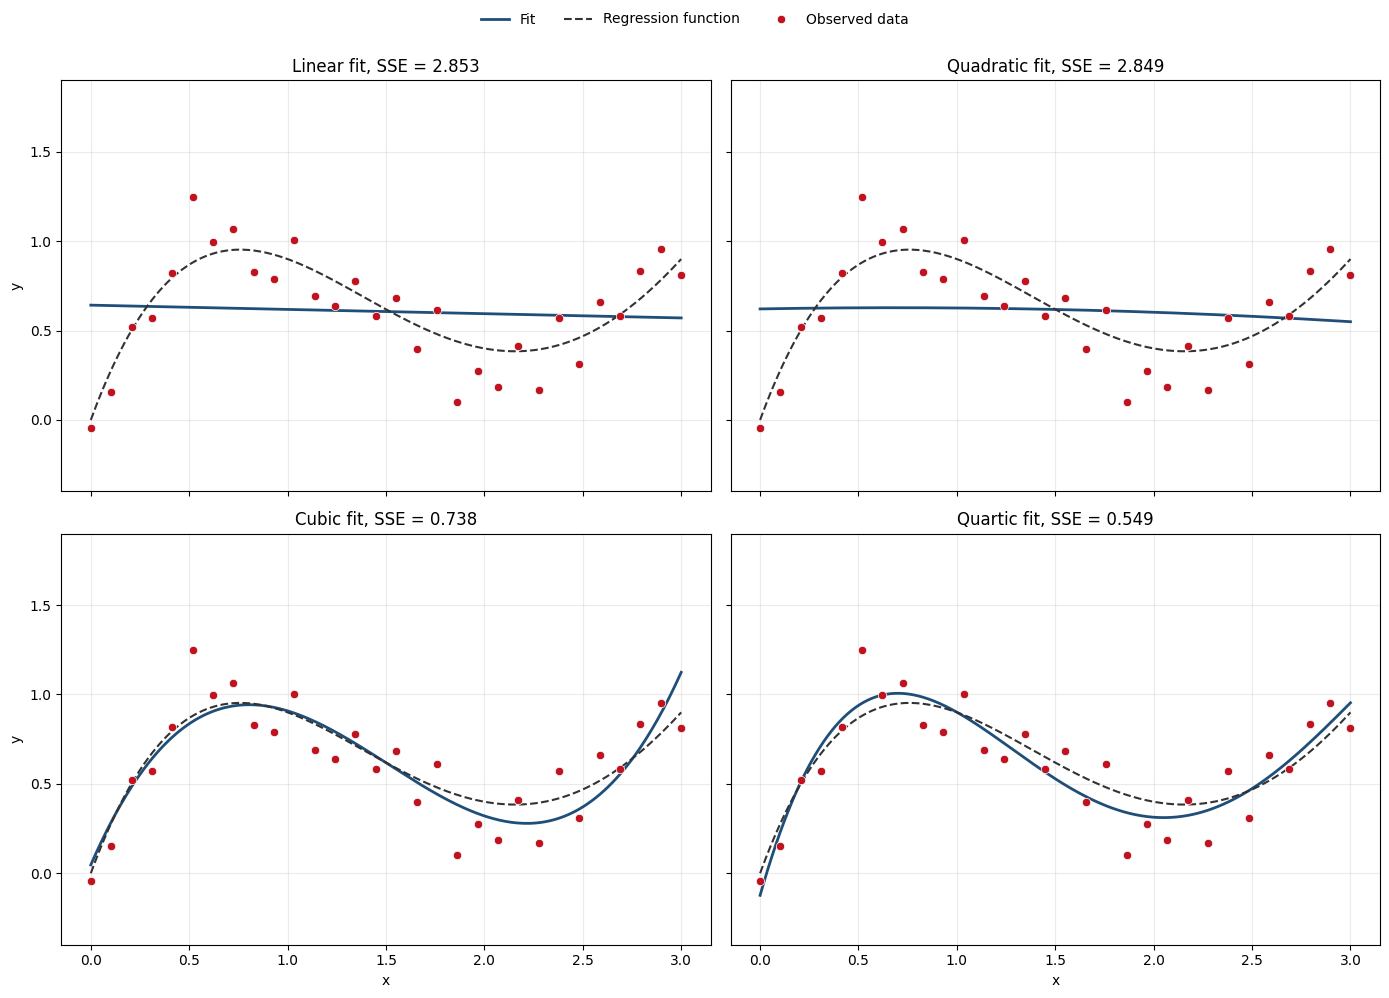

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
names = ['Linear', 'Quadratic', 'Cubic', 'Quartic']

for ax, degree, name in zip(axes.ravel(), range(1, 5), names):
    X = np.vstack([x**d for d in range(degree+1)]).T
    X_grid = np.vstack([x_grid**d for d in range(degree+1)]).T
    beta = np.linalg.lstsq(X, Y, rcond=None)[0]
    SSE = sum((Y - X @ beta)**2)

    ax.plot(x_grid, X_grid @ beta, color=line_color, lw=2, label='Fit')
    plot_data(ax, legend=False)
    ax.set_title(f'{name} fit, SSE = {SSE:.3f}')

for ax in axes[0]:
    ax.set_xlabel('')
for ax in axes[:, 1]:
    ax.set_ylabel('')
shared_legend(fig, axes[0, 0])

## Piecewise polynomials

Instead of one polynomial for the whole range, we split the range of $x$ at the knots $k_1 = 1$ and $k_2 = 2$ and fit a polynomial of degree $d$ in each of the three intervals. The design matrix is block diagonal,
$$X = \begin{pmatrix} A & 0 & 0 \\ 0 & B & 0 \\ 0 & 0 & C \end{pmatrix},$$
where $A$, $B$ and $C$ have the columns $1, x, \ldots, x^d$ for the observations of each interval.

In [8]:
knots = np.array([1, 2])

In [9]:
def piecewise_design(x, knots, degree):
    # Block design matrix: a polynomial of the given degree in each interval
    x = np.asarray(x, dtype=float)
    q = degree+1
    piece = np.searchsorted(knots, x, side='right')
    powers = np.vstack([x**d for d in range(q)]).T
    X = np.zeros((len(x), (len(knots)+1)*q))
    for j in range(len(knots)+1):
        X[piece == j, j*q:(j+1)*q] = powers[piece == j]
    return X

### Restricted least squares

The pieces do not need to agree at the knots. To force them, we write the restrictions as $K\beta = 0$. For example, with straight lines, continuity at $k_1$ and $k_2$ is
$$K = \begin{pmatrix} 1 & k_1 & -1 & -k_1 & 0 & 0 \\ 0 & 0 & 1 & k_2 & -1 & -k_2 \end{pmatrix}.$$
Continuity of the $r$-th derivative gives one more row per knot, built with the $r$-th derivative of $1, x, \ldots, x^d$.

The least squares estimator subject to $K\beta = 0$ is
$$\tilde\beta = \hat\beta - (X^TX)^{-1}K^T\left[K(X^TX)^{-1}K^T\right]^{-1}K\hat\beta,$$
with
$$\mathrm{Var}(\tilde\beta) = \sigma^2\left\{(X^TX)^{-1} - (X^TX)^{-1}K^T\left[K(X^TX)^{-1}K^T\right]^{-1}K(X^TX)^{-1}\right\}.$$
Each restriction gives back one degree of freedom: with $p$ coefficients and $q$ restrictions, $\hat\sigma^2 = SSE/(n-p+q)$.

In [10]:
def continuity_constraints(knots, degree, order):
    # Rows of K: continuity of the derivatives 0, 1, ..., order at each knot
    q = degree+1
    rows = []
    for r in range(order+1):
        for j, k in enumerate(knots):
            deriv = np.array([factorial(d)/factorial(d-r) * k**(d-r) if d >= r else 0 for d in range(q)])
            row = np.zeros((len(knots)+1)*q)
            row[j*q:(j+1)*q] = deriv
            row[(j+1)*q:(j+2)*q] = -deriv
            rows.append(row)
    return np.array(rows)

In [11]:
def restricted_ls(X, Y, K=None):
    # Least squares subject to K beta = 0. Returns beta, Var(beta)/sigma^2, sigma^2 estimate, degrees of freedom
    n, p = X.shape
    V = np.linalg.inv(X.T @ X)
    beta = V @ X.T @ Y
    q = 0
    if K is not None:
        q = K.shape[0]
        aux = V @ K.T
        beta = beta - aux @ np.linalg.solve(K @ aux, K @ beta)
        V = V - aux @ np.linalg.solve(K @ aux, aux.T)
    df = n - p + q
    s2 = sum((Y - X @ beta)**2)/df
    return beta, V, s2, df

In [12]:
def plot_piecewise(beta, V, s2, df, knots, degree, title):
    # Plot each piece with its confidence and prediction bands
    q = degree+1
    n_pieces = len(knots)+1
    edges = np.concatenate([[x_grid.min()], knots, [x_grid.max()]])
    q_t = t.ppf(1-alpha/2, df)
    ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
    pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'

    fig, ax = plt.subplots(figsize=(10, 7.5))
    pieces = []
    for j in range(n_pieces):
        x_piece = np.linspace(edges[j], edges[j+1], 100)
        X_piece = np.zeros((100, n_pieces*q))
        X_piece[:, j*q:(j+1)*q] = np.vstack([x_piece**d for d in range(q)]).T
        Y_piece_hat = X_piece @ beta
        h_piece = np.sum((X_piece @ V) * X_piece, axis=1)
        pieces.append((x_piece, Y_piece_hat, q_t*np.sqrt(s2*h_piece), q_t*np.sqrt(s2*(1+h_piece))))

    for j, (x_piece, Y_piece_hat, ci, pi) in enumerate(pieces):
        ax.fill_between(x_piece, Y_piece_hat-pi, Y_piece_hat+pi, color=pi_color, linewidth=0,
                        label=pi_label if j == 0 else None)
    for j, (x_piece, Y_piece_hat, ci, pi) in enumerate(pieces):
        ax.fill_between(x_piece, Y_piece_hat-ci, Y_piece_hat+ci, color=ci_color, alpha=0.7, linewidth=0,
                        label=ci_label if j == 0 else None)
    for j, (x_piece, Y_piece_hat, ci, pi) in enumerate(pieces):
        ax.plot(x_piece, Y_piece_hat, color=line_color, lw=2, label='Fit' if j == 0 else None)
    for k in knots:
        ax.axvline(k, ls=':', color=true_color, lw=1)
        ax.annotate('knot', (k, 0), xycoords=('data', 'axes fraction'), xytext=(4, 6),
                    textcoords='offset points', fontsize=9, color=true_color)
    plot_data(ax)
    ax.set_ylim(-0.6, 2.1)
    ax.set_title(title)

### Piecewise linear fit

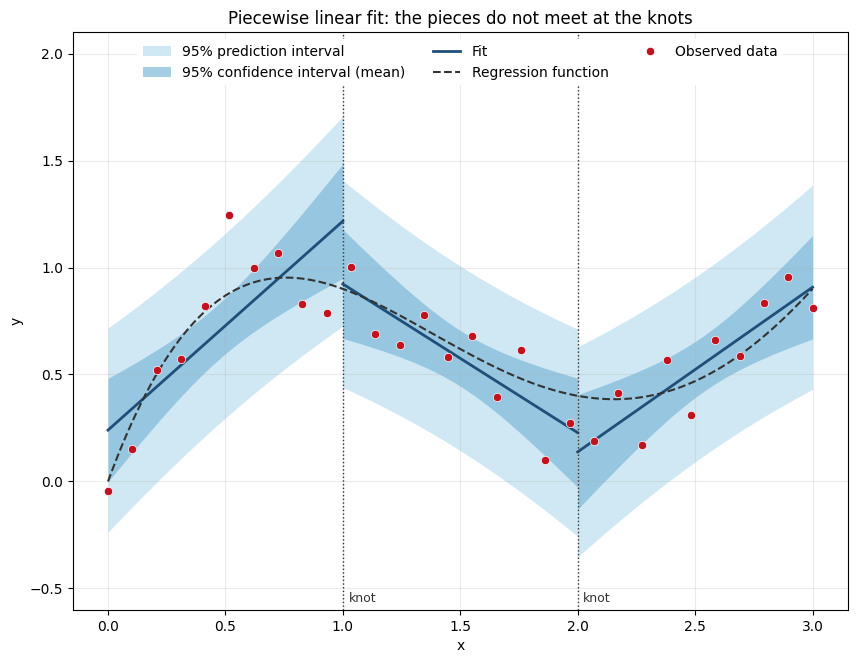

In [13]:
X = piecewise_design(x, knots, degree=1)
beta, V, s2, df = restricted_ls(X, Y)
plot_piecewise(beta, V, s2, df, knots, 1, 'Piecewise linear fit: the pieces do not meet at the knots')

### Piecewise linear fit, with continuity

In [14]:
K = continuity_constraints(knots, degree=1, order=0)
K

array([[ 1.,  1., -1., -1.,  0.,  0.],
       [ 0.,  0.,  1.,  2., -1., -2.]])

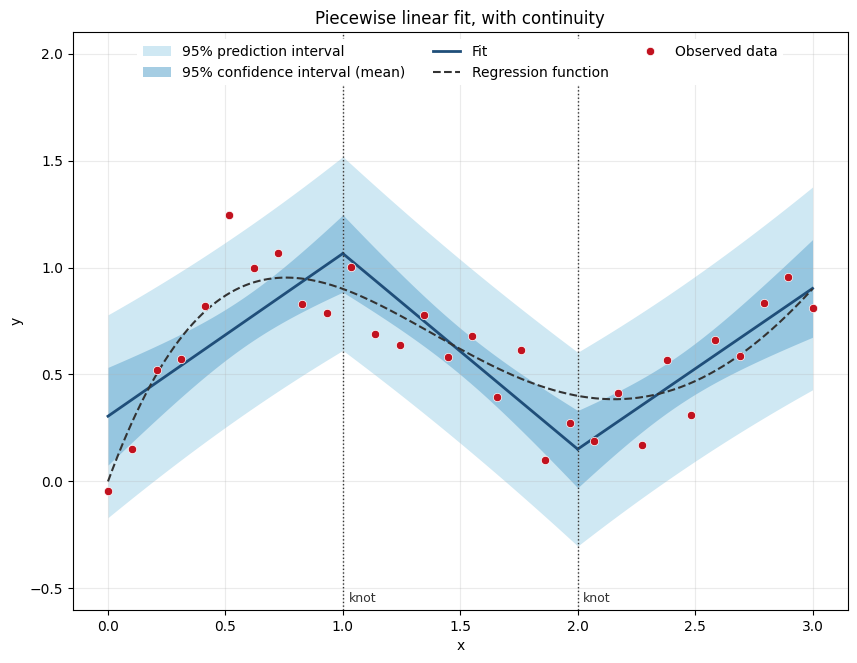

In [15]:
beta, V, s2, df = restricted_ls(X, Y, K)
plot_piecewise(beta, V, s2, df, knots, 1, 'Piecewise linear fit, with continuity')

### Piecewise cubic fit, with continuity

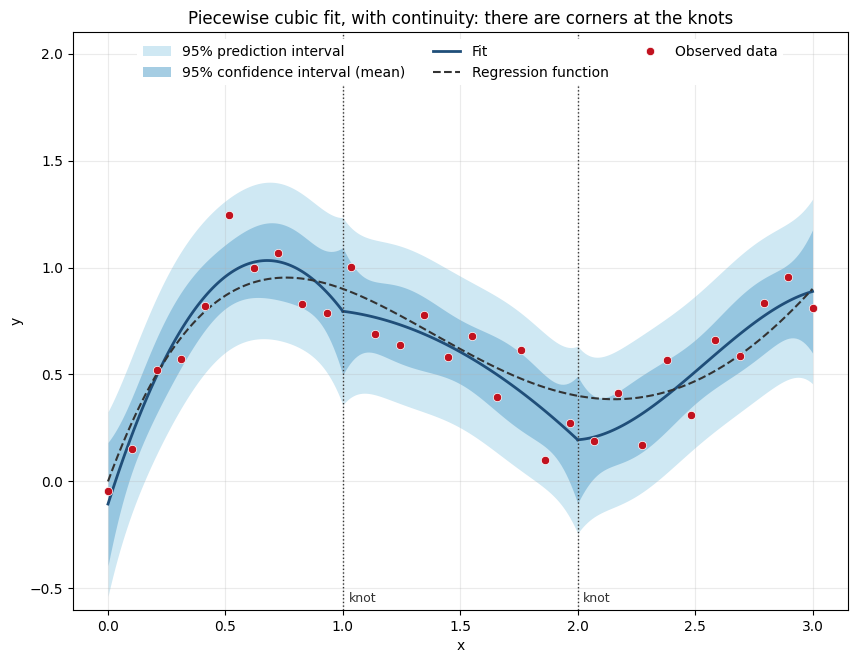

In [16]:
X = piecewise_design(x, knots, degree=3)
K = continuity_constraints(knots, degree=3, order=0)
beta, V, s2, df = restricted_ls(X, Y, K)
plot_piecewise(beta, V, s2, df, knots, 3, 'Piecewise cubic fit, with continuity: there are corners at the knots')

### Piecewise cubic fit, with continuity in the first derivative

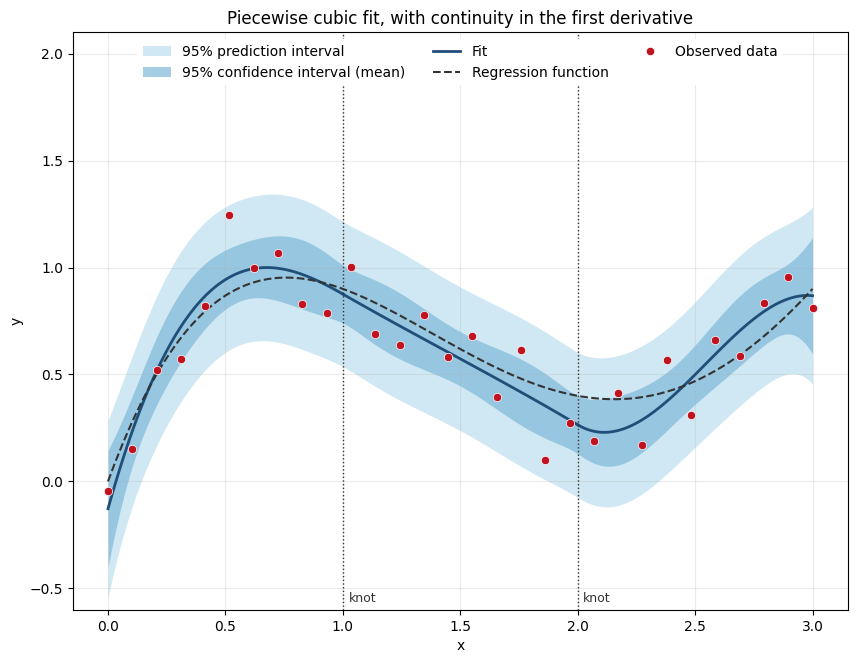

In [17]:
K = continuity_constraints(knots, degree=3, order=1)
beta, V, s2, df = restricted_ls(X, Y, K)
plot_piecewise(beta, V, s2, df, knots, 3, 'Piecewise cubic fit, with continuity in the first derivative')

### Cubic spline: continuity up to the second derivative

With 12 coefficients and 6 restrictions, the cubic spline with two knots has 6 free parameters.

In [18]:
K = continuity_constraints(knots, degree=3, order=2)
np.round(K, 2)

array([[  1.,   1.,   1.,   1.,  -1.,  -1.,  -1.,  -1.,   0.,   0.,   0.,
          0.],
       [  0.,   0.,   0.,   0.,   1.,   2.,   4.,   8.,  -1.,  -2.,  -4.,
         -8.],
       [  0.,   1.,   2.,   3.,  -0.,  -1.,  -2.,  -3.,   0.,   0.,   0.,
          0.],
       [  0.,   0.,   0.,   0.,   0.,   1.,   4.,  12.,  -0.,  -1.,  -4.,
        -12.],
       [  0.,   0.,   2.,   6.,  -0.,  -0.,  -2.,  -6.,   0.,   0.,   0.,
          0.],
       [  0.,   0.,   0.,   0.,   0.,   0.,   2.,  12.,  -0.,  -0.,  -2.,
        -12.]])

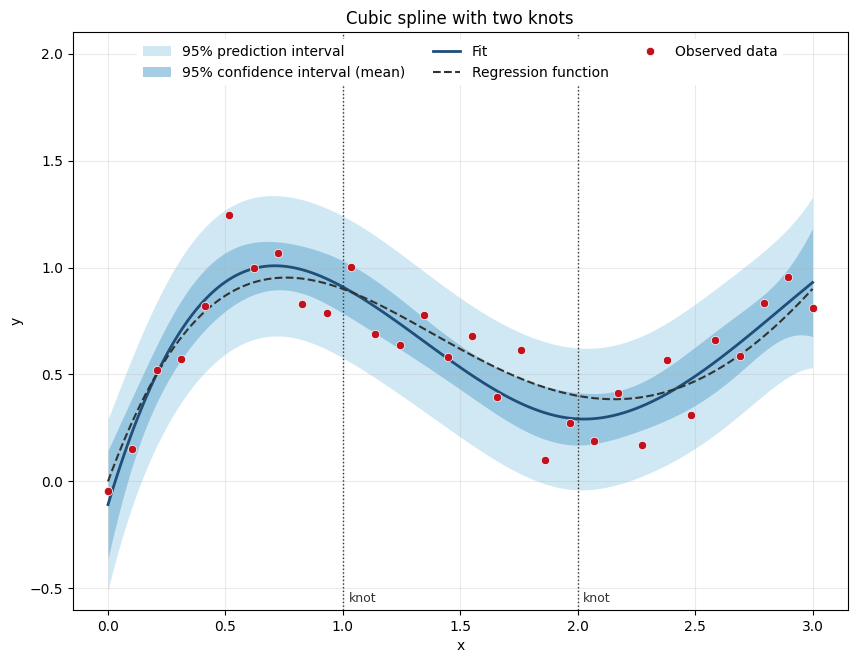

In [19]:
beta, V, s2, df = restricted_ls(X, Y, K)
Y_hat_restricted = X @ beta
plot_piecewise(beta, V, s2, df, knots, 3, 'Cubic spline with two knots')

## The same spline with a basis

The restrictions can be avoided using a basis of the space of cubic splines. The truncated power basis is
$$1,\ x,\ x^2,\ x^3,\ (x-k_1)_+^3,\ (x-k_2)_+^3,$$
six functions for the six free parameters, and the spline is fitted by ordinary least squares. The B-splines are another basis of the same space, numerically more stable, and the one used by `scipy`.

In [20]:
def truncated_power_basis(x, knots, degree=3):
    x = np.asarray(x, dtype=float)
    columns = [x**d for d in range(degree+1)] + [np.clip(x-k, 0, None)**degree for k in knots]
    return np.vstack(columns).T

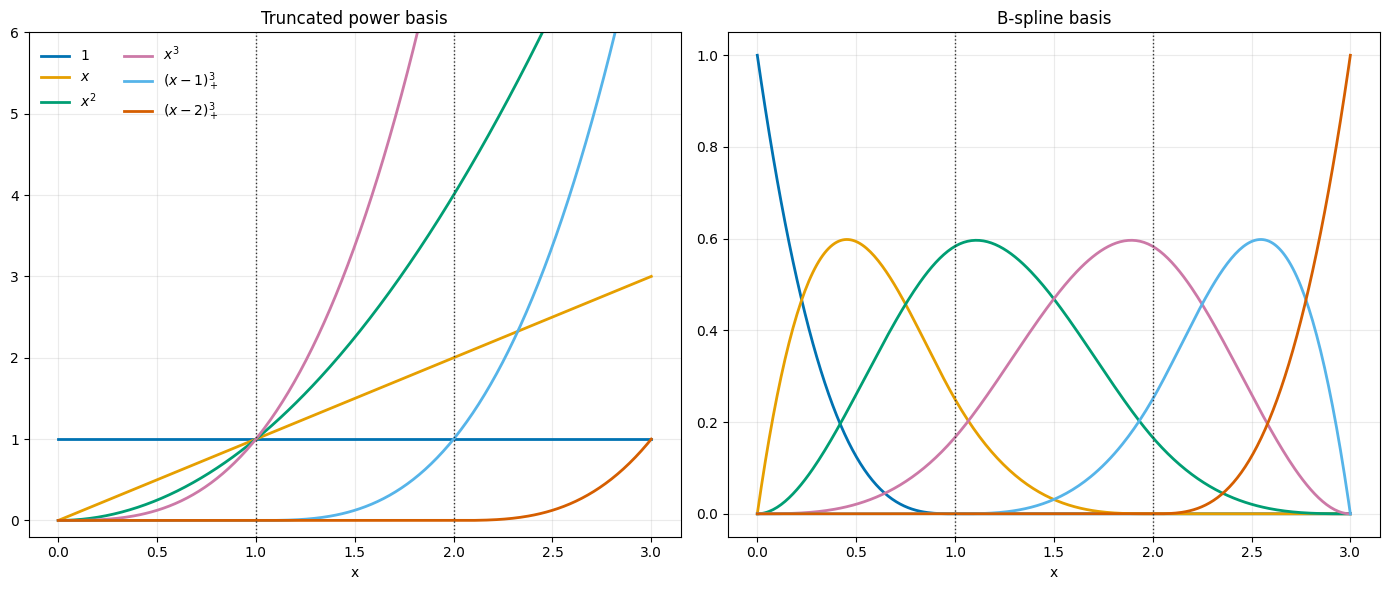

In [21]:
categorical = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#56B4E9', '#D55E00']

T_grid = truncated_power_basis(x_grid, knots)
t_full = np.concatenate([[0]*4, knots, [3]*4])       # knots of the B-splines, with the boundaries repeated
B_grid = BSpline.design_matrix(x_grid, t_full, 3).toarray()
labels = ['$1$', '$x$', '$x^2$', '$x^3$', '$(x-1)_+^3$', '$(x-2)_+^3$']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for j in range(6):
    axes[0].plot(x_grid, T_grid[:, j], color=categorical[j], lw=2, label=labels[j])
    axes[1].plot(x_grid, B_grid[:, j], color=categorical[j], lw=2)
axes[0].set_ylim(-0.2, 6)
axes[0].legend(loc='upper left', frameon=False, ncol=2)
axes[0].set_title('Truncated power basis')
axes[1].set_title('B-spline basis')
for ax in axes:
    for k in knots:
        ax.axvline(k, ls=':', color=true_color, lw=1)
    ax.set_xlabel('x')
    ax.grid(True, alpha=0.25)
plt.tight_layout()

The three ways of computing the spline give the same fitted values.

In [22]:
T = truncated_power_basis(x, knots)
Y_hat_basis = T @ np.linalg.lstsq(T, Y, rcond=None)[0]
Y_hat_scipy = LSQUnivariateSpline(x, Y, knots, k=3)(x)

print('Restricted least squares vs truncated power basis:', np.max(np.abs(Y_hat_restricted - Y_hat_basis)))
print('Restricted least squares vs scipy:                ', np.max(np.abs(Y_hat_restricted - Y_hat_scipy)))

Restricted least squares vs truncated power basis: 2.9916114030470453e-10
Restricted least squares vs scipy:                 2.991916714378817e-10


## How many knots?

With more knots the spline is more flexible. With too many it follows the noise instead of the regression function.

In [23]:
def fit_spline(n_knots, degree=3):
    # Spline with n_knots equally spaced interior knots, fitted with the truncated power basis
    knots = np.linspace(0, 3, n_knots+2)[1:-1]
    T = truncated_power_basis(x, knots, degree)
    beta = np.linalg.lstsq(T, Y, rcond=None)[0]
    return knots, truncated_power_basis(x_grid, knots, degree) @ beta, sum((Y - T @ beta)**2)

def plot_spline(ax, n_knots, degree=3, legend=True):
    knots, Y_grid_hat, SSE = fit_spline(n_knots, degree)
    for k in knots:
        ax.axvline(k, ls=':', color=true_color, lw=1, alpha=0.6)
    ax.plot(x_grid, Y_grid_hat, color=line_color, lw=2, label='Spline')
    plot_data(ax, legend)
    word = 'knot' if n_knots == 1 else 'knots'
    ax.set_title(f'{n_knots} {word}, {n_knots+degree+1} parameters, SSE = {SSE:.3f}')

Move the sliders to change the number of knots and the degree of the pieces (this cell needs a running kernel).

In [24]:
def interactive_spline(n_knots, degree):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    plot_spline(ax, n_knots, degree)
    plt.show()

interact(interactive_spline,
         n_knots=IntSlider(value=2, min=0, max=20, description='knots'),
         degree=IntSlider(value=3, min=1, max=3, description='degree'));

interactive(children=(IntSlider(value=2, description='knots', max=20), IntSlider(value=3, description='degree'…

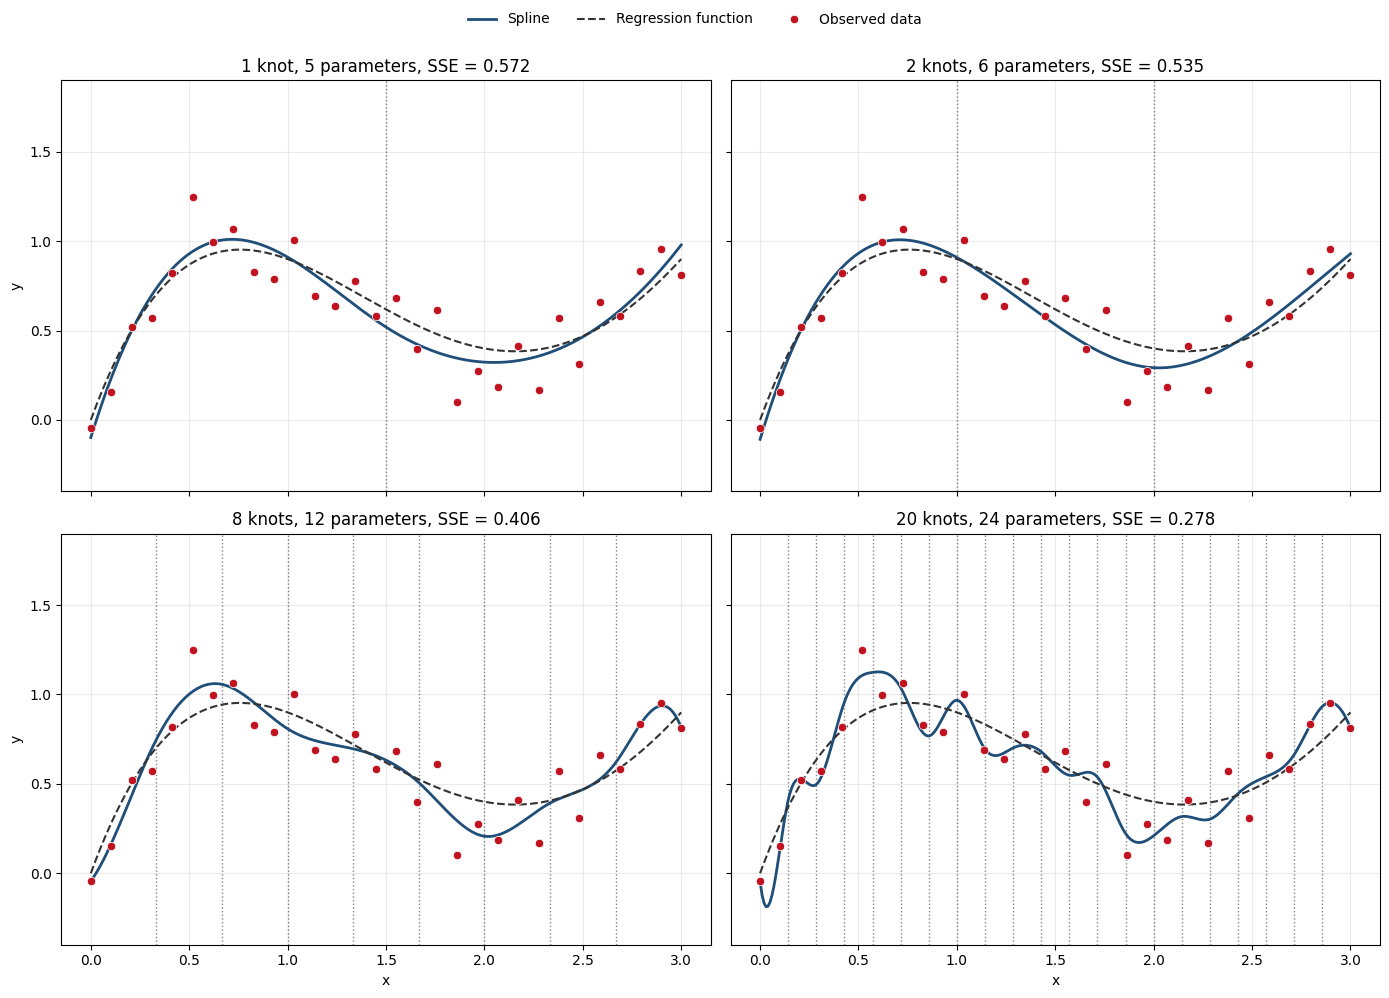

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
for ax, n_knots in zip(axes.ravel(), [1, 2, 8, 20]):
    plot_spline(ax, n_knots, legend=False)
for ax in axes[0]:
    ax.set_xlabel('')
for ax in axes[:, 1]:
    ax.set_ylabel('')
shared_legend(fig, axes[0, 0])